> Versión de portafolio. Se conservan las salidas históricas del trabajo académico. Las rutas absolutas de datos, cuando existían, se sustituyeron por nombres locales. Esta versión no se ha ejecutado de nuevo; consulte README y DATOS.md antes de reproducir.


# Tarea M 26-CD Javier Bueno Sanchez.

Preámbulo.

Con el uso de Clustering jerárquico haremos recomendaciones de compras a los clientes. La idea consiste en recomendar a un cliente los productos que ha comprado otra persona que pertenece al mismo clúster o segmento.

El objetivo de esta actividad es que realices un análisis de agrupación por “Clustering Jerárquico” a una base de datos de manera que  puedas generar conclusiones de acuerdo a diversas categorías.

Índice:

    1. Objetivo.

    2. Origen y contenido de la información.

    3. Importación de librerías y carga del conjunto de datos.

    4. Análisis exploratorio de los datos.

    5. Preparación de datos.

    6. Construcción de dendrograma con el método de Ward.

    7. Cálculo de cercanía.

    8. Conclusión.

    9. Inferencia del análisis.

    10. Análisis PCA.

<b>1. Objetivo.</b>
   
Realizar un análisis de agrupación por “Clustering Jerárquico” a una base de datos de manera que  puedas generar conclusiones de acuerdo a diversas categorías.

Con base en los resultados del análisis, 

A. ¿Qué productos recomendaría a Salomé? 

B. ¿Qué productos recomendaría a Stephanía? 

C. ¿Qué productos recomendaría a Lydia? La respuesta debe estar reflejada en función de otros clientes. 

Por ejemplo, “Recomendaría a Salomé los mismos productos que compró XXXXX”. Dé nombres de clientes en cada caso. Explique claramente sus conclusiones.

<b>2. Origen y contenido de la información.</b>

Extrae de internet la base de datos “Amazon.xlsx” de la siguiente liga y agregala a un DataFrame en Python.

https://github.com/JoseRaulCastro/EBAC/blob/main/Amazon.xlsx

El archivo “Amazon.xlsx” contiene los promedios de evaluación de 100 personas que adquirieron los mismos productos o muy similares en la tienda AMAZON.

<b>3. Importación de librerías y carga del conjunto de datos.</b>

In [1]:
# Manipulación de datos.
import pandas as pd

url = ("https://raw.githubusercontent.com/""JoseRaulCastro/EBAC/main/Amazon.xlsx")

df = pd.read_excel(url)

df.head()

,Unnamed: 0,Velocidad Entrega,Precio,Durabilidad,Imagen Producto,Valor Educativo,Servicio Retorno,Tamano Paquete,Calidad Producto,Numero Estrellas
0,Adam,205,3,345,235,24,23,26,21,17
1,Anna,9,15,315,33,25,4,42,215,28
2,Bernard,17,26,285,3,43,27,41,26,33
3,Edward,135,5,355,295,18,23,39,195,17
4,Emilia,3,45,48,39,34,46,225,34,43


<b>4. Análisis exploratorio de los datos.</b>

In [2]:
# Verificamos que el archivo contiene la evaluación de 100 personas.
print(f"Filas: {df.shape[0]}")
print(f"Columnas: {df.shape[1]}")

display(df.head())
df.info()

Filas: 100
Columnas: 10


,Unnamed: 0,Velocidad Entrega,Precio,Durabilidad,Imagen Producto,Valor Educativo,Servicio Retorno,Tamano Paquete,Calidad Producto,Numero Estrellas
0,Adam,205,3,345,235,24,23,26,21,17
1,Anna,9,15,315,33,25,4,42,215,28
2,Bernard,17,26,285,3,43,27,41,26,33
3,Edward,135,5,355,295,18,23,39,195,17
4,Emilia,3,45,48,39,34,46,225,34,43


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 10 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   Unnamed: 0         100 non-null    object
 1   Velocidad Entrega  100 non-null    int64 
 2   Precio             100 non-null    int64 
 3   Durabilidad        100 non-null    int64 
 4   Imagen Producto    100 non-null    int64 
 5   Valor Educativo    100 non-null    int64 
 6   Servicio Retorno   100 non-null    int64 
 7   Tamano Paquete     100 non-null    int64 
 8   Calidad Producto   100 non-null    int64 
 9   Numero Estrellas   100 non-null    int64 
dtypes: int64(9), object(1)
memory usage: 7.9+ KB


<b>5. Preparación de datos.</b>

In [3]:
# Asignamos el nombre Cliente a la columna que contiene los nombres de las personas.
df = df.rename(columns={"Unnamed: 0": "Cliente"})

display(df.head())

,Cliente,Velocidad Entrega,Precio,Durabilidad,Imagen Producto,Valor Educativo,Servicio Retorno,Tamano Paquete,Calidad Producto,Numero Estrellas
0,Adam,205,3,345,235,24,23,26,21,17
1,Anna,9,15,315,33,25,4,42,215,28
2,Bernard,17,26,285,3,43,27,41,26,33
3,Edward,135,5,355,295,18,23,39,195,17
4,Emilia,3,45,48,39,34,46,225,34,43


In [4]:
# Verificar nombres duplicados.
print(f"Clientes duplicados: {df['Cliente'].duplicated().sum()}")

# Verificar filas completamente duplicadas.
print(f"Filas duplicadas: {df.duplicated().sum()}")

# Resumen estadístico de las categorías.
display(df.describe().T)

# Buscar a los clientes solicitados.
clientes_objetivo = ["Salomé", "Stephanía", "Lydia"]

for nombre in clientes_objetivo:
    coincidencias = df[
        df["Cliente"].str.contains(nombre, case=False, na=False)]
    display(coincidencias)

Clientes duplicados: 0
Filas duplicadas: 0


,count,mean,std,min,25%,50%,75%,max
Velocidad Entrega,100.0,91.24,95.021223,0.0,15.00,26.0,167.5,305.0
Precio,100.0,58.35,65.009615,1.0,9.00,22.5,95.0,225.0
Durabilidad,100.0,238.10,188.035699,3.0,41.00,295.0,417.5,495.0
Imagen Producto,100.0,143.87,121.765519,2.0,25.00,150.0,245.0,355.0
Valor Educativo,100.0,25.56,11.288074,2.0,21.00,27.5,34.0,46.0
Servicio Retorno,100.0,23.86,9.631619,3.0,19.00,25.0,28.0,46.0
Tamano Paquete,100.0,155.77,163.857653,3.0,32.50,42.0,320.0,495.0
Calidad Producto,100.0,129.20,110.628234,2.0,24.00,165.0,227.5,335.0
Numero Estrellas,100.0,28.22,11.720292,1.0,22.75,30.0,36.5,48.0


,Cliente,Velocidad Entrega,Precio,Durabilidad,Imagen Producto,Valor Educativo,Servicio Retorno,Tamano Paquete,Calidad Producto,Numero Estrellas


,Cliente,Velocidad Entrega,Precio,Durabilidad,Imagen Producto,Valor Educativo,Servicio Retorno,Tamano Paquete,Calidad Producto,Numero Estrellas


,Cliente,Velocidad Entrega,Precio,Durabilidad,Imagen Producto,Valor Educativo,Servicio Retorno,Tamano Paquete,Calidad Producto,Numero Estrellas
54,Lydia,19,4,435,145,16,21,28,185,24


Observamos que dos de los nombres no aparecen, podemos deducir que hay alguna diferencia en la escritura.

In [5]:
# Importación de librería para eliminar acentos y espacios.
import unicodedata

def normalizar_texto(texto):
    texto = str(texto).strip().lower()
    return "".join(
        caracter
        for caracter in unicodedata.normalize("NFD", texto)
        if unicodedata.category(caracter) != "Mn")

df["Cliente_busqueda"] = df["Cliente"].apply(normalizar_texto)

for nombre in ["Salome", "Stephania", "Lydia"]:
    coincidencias = df[df["Cliente_busqueda"].str.contains(normalizar_texto(nombre), na=False)]
    
    display(coincidencias)

,Cliente,Velocidad Entrega,Precio,Durabilidad,Imagen Producto,Valor Educativo,Servicio Retorno,Tamano Paquete,Calidad Producto,Numero Estrellas,Cliente_busqueda
81,Salome,17,23,275,41,4,44,315,28,32,salome


,Cliente,Velocidad Entrega,Precio,Durabilidad,Imagen Producto,Valor Educativo,Servicio Retorno,Tamano Paquete,Calidad Producto,Numero Estrellas,Cliente_busqueda
89,Stephania,215,125,465,315,34,4,37,305,45,stephania


,Cliente,Velocidad Entrega,Precio,Durabilidad,Imagen Producto,Valor Educativo,Servicio Retorno,Tamano Paquete,Calidad Producto,Numero Estrellas,Cliente_busqueda
54,Lydia,19,4,435,145,16,21,28,185,24,lydia


In [6]:
# Separación de los nombres de las variables numéricas y estandarización de los datos.
from sklearn.preprocessing import StandardScaler

# Conservar únicamente las nueve categorías numéricas.
X = df.drop(columns=["Cliente", "Cliente_busqueda"])

# Crear y aplicar el escalador.
escalador = StandardScaler()
X_escalado = escalador.fit_transform(X)

# Convertir el resultado nuevamente en un DataFrame.
X_escalado = pd.DataFrame(X_escalado, columns=X.columns, index=df.index)

display(X_escalado.head())

,Velocidad Entrega,Precio,Durabilidad,Imagen Producto,Valor Educativo,Servicio Retorno,Tamano Paquete,Calidad Producto,Numero Estrellas
0,1.203238,-0.855702,0.571373,0.752176,-0.138895,-0.089739,-0.795958,-0.982978,-0.962137
1,-0.869851,-0.670184,0.411025,-0.915108,-0.049860,-2.072346,-0.697820,0.779478,-0.018865
2,-0.785235,-0.500126,0.250677,-1.162724,1.552777,0.327652,-0.703954,-0.937554,0.409894
3,0.462849,-0.824782,0.624822,1.247409,-0.673107,-0.089739,-0.716221,0.597781,-0.962137
4,-0.933313,-0.206389,-1.016071,-0.865584,0.751459,2.310259,0.424629,-0.864875,1.267414


In [7]:
verificacion_escalado = pd.DataFrame({
    "Media": X_escalado.mean(),
    "Desviación estándar": X_escalado.std(ddof=0)})

display(verificacion_escalado.round(4))

,Media,Desviación estándar
Velocidad Entrega,0.0,1.0
Precio,-0.0,1.0
Durabilidad,0.0,1.0
Imagen Producto,-0.0,1.0
Valor Educativo,0.0,1.0
Servicio Retorno,0.0,1.0
Tamano Paquete,-0.0,1.0
Calidad Producto,0.0,1.0
Numero Estrellas,0.0,1.0


<b>6. Construcción de dendrograma con el método de Ward.</b>

Nota explicativa:

linkage() inicia considerando cada cliente como un clúster independiente y después va uniendo los grupos.

Usamos:

method="ward": une los grupos procurando que el incremento de variabilidad interna sea el menor posible.

metric="euclidean": calcula la distancia en línea recta entre los perfiles estandarizados.

labels=df["Cliente"].values: muestra los nombres en lugar de los índices.

A continuación se presenta el dendrograma construido mediante el método de Ward y distancia euclidiana sobre las variables estandarizadas. Su estructura permitirá identificar posibles agrupaciones y analizar los principales saltos en las distancias de fusión.

<div style="break-before: page; page-break-before: always;"></div>

In [8]:
# Importamos librerías para crear dendrograma y visualizarlo.
from scipy.cluster.hierarchy import linkage, dendrogram
import matplotlib.pyplot as plt

# Calcular la estructura jerárquica.
Z = linkage(X_escalado, method="ward", metric="euclidean")

# Crear el dendrograma.
plt.figure(figsize=(15, 6.5))

dendrogram(Z, labels=df["Cliente"].values, leaf_rotation=90, leaf_font_size=7)

plt.title("Dendrograma de clientes de Amazon",fontsize=15, pad=12)
plt.xlabel("Clientes", fontsize=11)
plt.ylabel("Distancia de agrupamiento", fontsize=11)
plt.tight_layout()
plt.savefig("dendrograma_amazon.png", dpi=300, bbox_inches="tight", facecolor="white")
plt.close()

<div style="break-before: page; page-break-before: always;"></div>

<img src="dendrograma_amazon.png"
     style="display:block; width:95%; max-height:175mm; object-fit:contain; margin:auto;">

<div style="break-after: page; page-break-after: always;"></div>

<div style="break-after: page; page-break-after: always;"></div>

In [9]:
# Examen de las últimas uniones del clustering.
ultimas_uniones = pd.DataFrame(
    Z[-10:],
    columns=["Grupo 1", "Grupo 2", "Distancia", "Observaciones"])

display(ultimas_uniones.round(3))

,Grupo 1,Grupo 2,Distancia,Observaciones
0,112.0,178.0,7.130,9.0
1,179.0,182.0,7.173,15.0
2,183.0,188.0,7.609,21.0
3,172.0,184.0,7.750,19.0
4,186.0,190.0,8.456,24.0
5,185.0,191.0,8.770,36.0
6,187.0,189.0,8.975,21.0
7,193.0,195.0,10.151,45.0
8,194.0,196.0,13.399,81.0
9,192.0,197.0,13.950,100.0


In [10]:
# Comparativa de varias alternativas con el coeficiente de silueta.
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score

resultados = []

for k in range(2, 7):

    modelo = AgglomerativeClustering(n_clusters=k,linkage="ward")

    etiquetas = modelo.fit_predict(X_escalado)

    silueta = silhouette_score(X_escalado, etiquetas)

    resultados.append({"Número de clústeres": k, "Coeficiente de silueta": silueta})

resultados_cluster = pd.DataFrame(resultados)

display(resultados_cluster.sort_values("Coeficiente de silueta",ascending=False).round(4))

,Número de clústeres,Coeficiente de silueta
0,2,0.1095
1,3,0.1084
2,4,0.1077
3,5,0.1067
4,6,0.0986


In [11]:
# Comparativa del tamaño de los grupos y la ubicación de los tres clientes objetivo.
resultados_comparacion = []

for k in [2, 3]:
    modelo = AgglomerativeClustering( n_clusters=k, linkage="ward")

    etiquetas = modelo.fit_predict(X_escalado)

    columna_cluster = f"Cluster_{k}"
    df[columna_cluster] = etiquetas

    tamaños = (df[columna_cluster].value_counts().sort_index())

    for cluster, cantidad in tamaños.items():
        resultados_comparacion.append({"Número de clústeres": k, "Clúster": cluster, 
                                       "Cantidad de clientes": cantidad})

display(pd.DataFrame(resultados_comparacion))

,Número de clústeres,Clúster,Cantidad de clientes
0,2,0,81
1,2,1,19
2,3,0,45
3,3,1,19
4,3,2,36


In [12]:
# Se verifica el cluster donde quedan los clientes indicados.
clientes_objetivo = ["Salome", "Stephania", "Lydia"]

display(df.loc[df["Cliente"].isin(clientes_objetivo),["Cliente", "Cluster_2", "Cluster_3"]])

,Cliente,Cluster_2,Cluster_3
54,Lydia,0,2
81,Salome,0,0
89,Stephania,1,1


<b>Conclusión.</b>

Se seleccionó una solución de tres clústeres. Aunque dos clústeres alcanzaron un coeficiente de silueta ligeramente superior, la diferencia fue de apenas 0.0011. La solución de tres clústeres coincide con el principal salto observado en el dendrograma y proporciona una segmentación más específica: separa a Salome y Lydia, quienes con dos clústeres quedaban dentro de un grupo de 81 clientes. Stephania mantiene su asignación en ambas soluciones. No obstante, debido a los bajos coeficientes de silueta, los grupos deben interpretarse como aproximaciones de similitud y no como segmentos fuertemente separados.

<b>7. Cálculo de cercanía.<b/>

In [13]:
# Calculo de cuáles son los clientes más cercanos a cada cliente objetivo dentro de su grupo.
from sklearn.metrics import pairwise_distances

# Matriz de distancias entre todos los clientes.
matriz_distancias = pairwise_distances(X_escalado,metric="euclidean")

distancias_df = pd.DataFrame(matriz_distancias, index=df["Cliente"], columns=df["Cliente"])

clientes_objetivo = ["Salome", "Stephania", "Lydia"]

for cliente in clientes_objetivo:

    # Identificar el clúster del cliente objetivo.
    cluster_cliente = df.loc[df["Cliente"] == cliente, "Cluster_3"].iloc[0]

    # Obtener los integrantes del mismo clúster.
    mismo_cluster = df.loc[df["Cluster_3"] == cluster_cliente, "Cliente"]

    # Ordenar por distancia y excluir al propio cliente.
    clientes_similares = (distancias_df.loc[cliente, mismo_cluster].drop(cliente) .sort_values().head(5))

    print(f"\nCliente objetivo: {cliente}")
    print(f"Clúster: {cluster_cliente}")
    display(clientes_similares.rename("Distancia").to_frame().round(4))


Cliente objetivo: Salome
Clúster: 0


,Distancia
Cliente,
Magdalyna,2.7670
Henry,2.9736
Susanna,3.0002
Myron,3.1277
Emilia,3.1600



Cliente objetivo: Stephania
Clúster: 1


,Distancia
Cliente,
Judith,1.4000
Helen,1.9141
Maura,2.2408
Mykyta,2.7913
Markian,3.0113



Cliente objetivo: Lydia
Clúster: 2


,Distancia
Cliente,
Lubomyr,1.5073
Fialka,1.6756
Edward,1.9156
Fedir,1.9833
Irene,2.0094


<b>8. Conclusión.</b>

Se seleccionó una solución de tres clústeres porque, aunque dos clústeres obtuvieron un coeficiente de silueta ligeramente superior, la diferencia fue mínima (0.0011) y la división en tres grupos coincide con el principal salto observado en el dendrograma. Sin embargo, los bajos valores de silueta indican que la separación entre los grupos es débil, por lo que no pueden considerarse segmentos claramente diferenciados.

El clustering agrupó a los clientes de acuerdo con la similitud de sus evaluaciones en nueve categorías, como precio, calidad del producto, durabilidad, imagen del producto, valor educativo, servicio de retorno, tamaño del paquete, número de estrellas y velocidad de entrega. Por tanto, los resultados representan principalmente perfiles similares de preferencias y exigencias sobre los productos y el servicio, no similitudes comprobadas entre productos específicos.

Dentro de cada clúster se calculó la distancia euclidiana entre los perfiles estandarizados. Con este criterio, Magdalyna es el cliente más parecido a Salomé, con una distancia de 2.7670; Judith es la referencia más cercana para Stephania, con 1.4000; y Lubomyr para Lydia, con 1.5073.

En respuesta a lo solicitado, se tomarían como referencia para una posible recomendación los productos adquiridos por Magdalyna para Salome, por Judith para Stephania y por Lubomyr para Lydia. Esta propuesta parte de la inferencia de que clientes con perfiles de evaluación semejantes podrían mostrar interés por productos similares, relación que no está demostrada directamente por los datos disponibles.

No obstante, la base de datos no identifica los productos adquiridos, las calificaciones individuales otorgadas a cada artículo ni cuáles productos todavía no ha comprado cada cliente. En consecuencia, el análisis permite seleccionar clientes de referencia, pero no demostrar qué productos concretos deberían recomendarse. Las propuestas deben entenderse como aproximaciones derivadas de la similitud entre perfiles y no como recomendaciones de compra plenamente validadas.

<b>9. Inferencia del análisis.<b/>

Los datos demuestran similitud entre perfiles de evaluación. A partir de esta evidencia se infiere que clientes con preferencias y niveles de exigencia semejantes podrían mostrar interés por productos similares; sin embargo, esta relación no está demostrada directamente por la información disponible.

<b>10. Ánalisis PCA.</b>

Nota explicativa:

PCA(): calcula tantos componentes como variables originales: en este caso, nueve.

fit(X_escalado): identifica las direcciones que concentran mayor variabilidad.

explained_variance_ratio_: indica qué proporción aporta cada componente.

cumsum(): muestra la información acumulada al añadir componentes.

In [14]:
from sklearn.decomposition import PCA

# Ajustar PCA sobre las nueve variables estandarizadas
pca = PCA()
pca.fit(X_escalado)

# Varianza explicada por cada componente
varianza_explicada = pd.DataFrame({
    "Componente": range(1, len(pca.explained_variance_ratio_) + 1),
    "Varianza explicada": pca.explained_variance_ratio_,
    "Varianza acumulada": pca.explained_variance_ratio_.cumsum()})

display(varianza_explicada.round(4))

,Componente,Varianza explicada,Varianza acumulada
0,1,0.1937,0.1937
1,2,0.1672,0.3609
2,3,0.1251,0.4860
3,4,0.1191,0.6051
4,5,0.1066,0.7117
5,6,0.0881,0.7998
6,7,0.0828,0.8827
7,8,0.0722,0.9548
8,9,0.0452,1.0000


Conclusión provisional del primer análisis:

Los dos primeros componentes principales explican conjuntamente el 36.09 % de la variabilidad total. En consecuencia, una representación bidimensional mediante PCA conservará poco más de un tercio de la información original y deberá interpretarse únicamente como una visualización complementaria, no como una validación definitiva de la separación entre clústeres.

In [15]:
# Se crean nuevamente las columnas numericas a partir de las variables originales, excluyendo el nombre del cliente y los clústeres añadidos
columnas_numericas = (df.drop(columns=["Cliente", "Cluster_2", "Cluster_3"],
        errors="ignore").select_dtypes(include="number").columns.tolist())

print(columnas_numericas)
print("Número de variables:", len(columnas_numericas))

['Velocidad Entrega', 'Precio', 'Durabilidad', 'Imagen Producto', 'Valor Educativo', 'Servicio Retorno', 'Tamano Paquete', 'Calidad Producto', 'Numero Estrellas']
Número de variables: 9


In [16]:
# Identificamos las que construyen PC1 y PC2.

assert X_escalado.shape[1] == len(columnas_numericas), ("El número de variables no coincide con las columnas utilizadas en PCA.")

# Contribución de las variables a cada componente.
cargas_pca = pd.DataFrame( pca.components_.T, index=columnas_numericas, columns=[
        f"PC{i}"
        for i in range(1, len(columnas_numericas) + 1)])

display(cargas_pca[["PC1", "PC2"]].assign(
        Importancia_PC1=lambda x: x["PC1"].abs(),
        Importancia_PC2=lambda x: x["PC2"].abs()).sort_values("Importancia_PC1",ascending=False).round(4))

,PC1,PC2,Importancia_PC1,Importancia_PC2
Numero Estrellas,0.5066,0.4345,0.5066,0.4345
Velocidad Entrega,0.4941,-0.0886,0.4941,0.0886
Valor Educativo,0.4900,0.2964,0.4900,0.2964
Calidad Producto,0.3176,-0.1510,0.3176,0.1510
Durabilidad,0.2825,-0.3054,0.2825,0.3054
Tamano Paquete,-0.2264,0.5233,0.2264,0.5233
Imagen Producto,0.1324,-0.2456,0.1324,0.2456
Servicio Retorno,-0.0964,0.2855,0.0964,0.2855
Precio,-0.0206,0.4286,0.0206,0.4286


Conclusión provisional de la contribución de variables:

El primer componente principal está determinado principalmente por el número de estrellas, la velocidad de entrega y el valor educativo, con aportaciones adicionales de la calidad y la durabilidad. Por ello, puede interpretarse de forma aproximada como una dimensión de valoración general del producto y del servicio.

El segundo componente está influido principalmente por el tamaño del paquete, el número de estrellas y el precio, en dirección opuesta a variables como la durabilidad y la imagen del producto. Este componente representa un contraste entre distintos criterios de evaluación, pero no presenta una interpretación de negocio única.

Debido a que PC1 y PC2 explican conjuntamente solo el 36.09 % de la variabilidad, estas interpretaciones describen únicamente una parte de los perfiles originales.

In [17]:
# Realizamos verificación de coordenadas.

# Obtener las coordenadas de cada cliente en PC1 y PC2
coordenadas_pca = pca.transform(X_escalado)[:, :2]

df_pca = pd.DataFrame(coordenadas_pca, columns=["PC1", "PC2"])

df_pca["Cliente"] = df["Cliente"].values
df_pca["Cluster_3"] = df["Cluster_3"].values

display(df_pca.head())

,PC1,PC2,Cliente,Cluster_3
0,0.194334,-1.585609,Adam,2
1,0.150354,-1.208414,Anna,2
2,0.337626,0.569334,Bernard,0
3,0.130811,-2.000005,Edward,2
4,-0.441908,2.302930,Emilia,0


In [18]:
# Antes de graficar, se valida que no se alteró el orden de los clientes:

assert len(df_pca) == len(df), ("El número de filas no coincide.")

assert (df_pca["Cliente"].values == 
        df["Cliente"].values).all(), ("Los clientes no conservaron el mismo orden.")

assert df_pca[["PC1", "PC2", 
               "Cluster_3"]].notna().all().all(), ("Existen valores faltantes en la tabla PCA.")

Al no obtener ningún mensaje, ejecutamos la gráfica.

<div style="break-before: page; page-break-before: always;"></div>

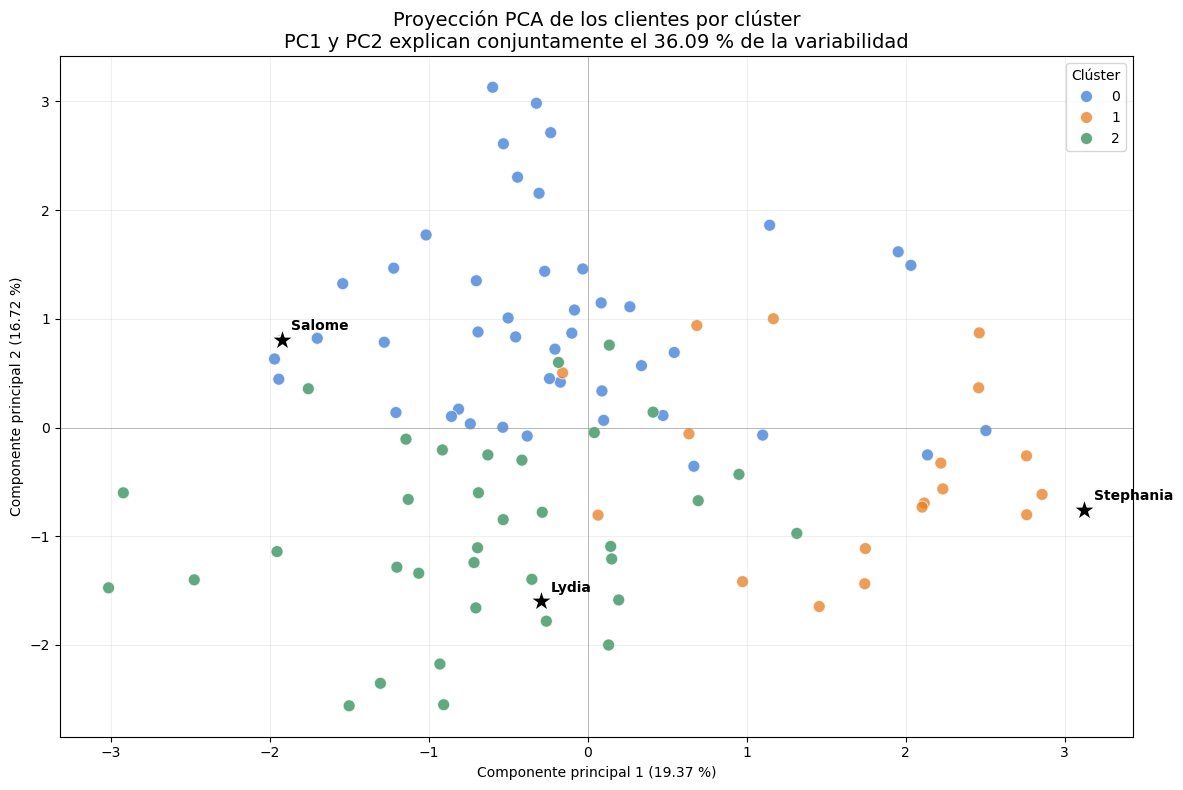

In [19]:
# Se importa librería para visualización.
import seaborn as sns
# Clientes que solicita analizar la actividad
clientes_objetivo = ["Salome", "Stephania", "Lydia"]

faltantes = set(clientes_objetivo) - set(df_pca["Cliente"])

assert not faltantes, (
    f"No se encontraron estos clientes: {faltantes}")

plt.figure(figsize=(12, 8))

sns.scatterplot(data=df_pca, x="PC1", y="PC2", hue="Cluster_3", 
                palette={ 0: "#3A7BD5", 1: "#E67E22", 2: "#2E8B57"}, s=75, alpha=0.75)

# Destacar los tres clientes objetivo
for _, fila in df_pca[
    df_pca["Cliente"].isin(clientes_objetivo)].iterrows():

    plt.scatter(fila["PC1"], fila["PC2"], marker="*", 
                s=300,color="black", edgecolor="white", linewidth=1.2, zorder=5)

    plt.annotate(fila["Cliente"], (fila["PC1"], fila["PC2"]), xytext=(7, 7), 
                 textcoords="offset points", fontsize=10, fontweight="bold")

plt.axhline(0, color="gray", linewidth=0.7, alpha=0.5)
plt.axvline(0, color="gray", linewidth=0.7, alpha=0.5)

plt.title("Proyección PCA de los clientes por clúster\n" "PC1 y PC2 explican conjuntamente el 36.09 % de la variabilidad", fontsize=14)

plt.xlabel("Componente principal 1 (19.37 %)")
plt.ylabel("Componente principal 2 (16.72 %)")
plt.legend(title="Clúster")
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

<div style="break-after: page; page-break-after: always;"></div>

<b>Referencia sobre los clientes objetivo:<b/>

<b>Salome:<b/> 
Aparece en una zona predominantemente asociada al clúster 0, aunque cercana a observaciones del clúster 2.

<b>Stephania:<b/> 
Ocupa una posición periférica, claramente hacia la región donde se concentra el clúster 1.

<b>Lydia:<b/> 
Se encuentra dentro de la región inferior ocupada principalmente por el clúster 2.

<b>Conclusión análisis:<b/>

La proyección PCA muestra ciertas tendencias en la distribución de los tres clústeres. El clúster 0 se concentra principalmente en la región superior y central; el clúster 1, hacia valores positivos de PC1; y el clúster 2, en la región inferior e izquierda. No obstante, se observa una superposición considerable, especialmente alrededor del centro de la gráfica.

Esta mezcla visual es coherente con los bajos coeficientes de silueta obtenidos anteriormente y respalda la conclusión de que los grupos representan perfiles aproximados, no segmentos claramente separados.

Salome se ubica en una zona predominantemente asociada al clúster 0, aunque próxima a observaciones de otro grupo. Stephania presenta la posición más periférica y se localiza en la región ocupada principalmente por el clúster 1. Lydia aparece dentro de la zona inferior correspondiente mayoritariamente al clúster 2.

Debido a que PC1 y PC2 explican conjuntamente solo el 36.09 % de la variabilidad, esta representación conserva poco más de un tercio de la información original. Por ello, PCA aporta una lectura visual de las tendencias y la superposición entre los grupos, pero no permite validar por sí solo la calidad del clustering ni sustituye las distancias calculadas con las nueve variables estandarizadas.

<b>Conclusión sobre PCA:</b> 

La proyección PCA es coherente con la débil separación señalada por la silueta, pero no modifica las recomendaciones ni demuestra similitud entre productos.